<h1><center>Multi-layer Perceptron</center></h1>

In this mini-project, we will implement a simple one hidden layer neural network from scratch.
Even if you will use deep learning libraries like Pytorch or Tensorflow later, implementing a network from scratch at least once is an extremely useful exercise, essential for designing and optimizing your own models effectively.


In [1]:
!pip install numpy
!pip install sklearn

# Imports of useful packages
import matplotlib # For the plots
import matplotlib.pyplot as plt 
import numpy as np # To perform operations on matrices efficiently


# We will use the sklearn library to compare our neural network to that 
# of a simpler approach like logistic regression

import sklearn 
import sklearn.datasets
import sklearn.linear_model

from math import exp,log

# To display plots inline and adjust the display

%matplotlib inline
matplotlib.rcParams['figure.figsize'] = (10.0, 8.0)

  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... error
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SK

# Generating a dataset

Let's start by generating a dataset that we can play with. The scikit-learn machine learning library has a few useful data generators, saving us the trouble of writing the code ourselves. We will use the make_moons function, which creates a two-class dataset of two-dimensional examples in the shape of two half-moons: each of the half-moons corresponds to a class.

In [62]:
np.random.seed(1)
X, y = sklearn.datasets.make_moons(n_samples=300, noise=0.20)  # We create a dataset with 300 elements


 <font color='red'><b>Question 1.</b></font> Show the coordinates and labels of the first two elements of the dataset.



In [63]:
# Question 1: X contains coordinates and y contains the labels.
print(f"The first coordinate point {X[0]} has a label {y[0]}")
print(f"The second coordinate point {X[1]} has a label {y[1]}")

The first coordinate point [ 0.21073485 -0.0159868 ] has a label 1
The second coordinate point [-0.82910413  0.65187765] has a label 0


We can display this dataset easily using Matplotlib using colors to make the labels appear $y$ : 

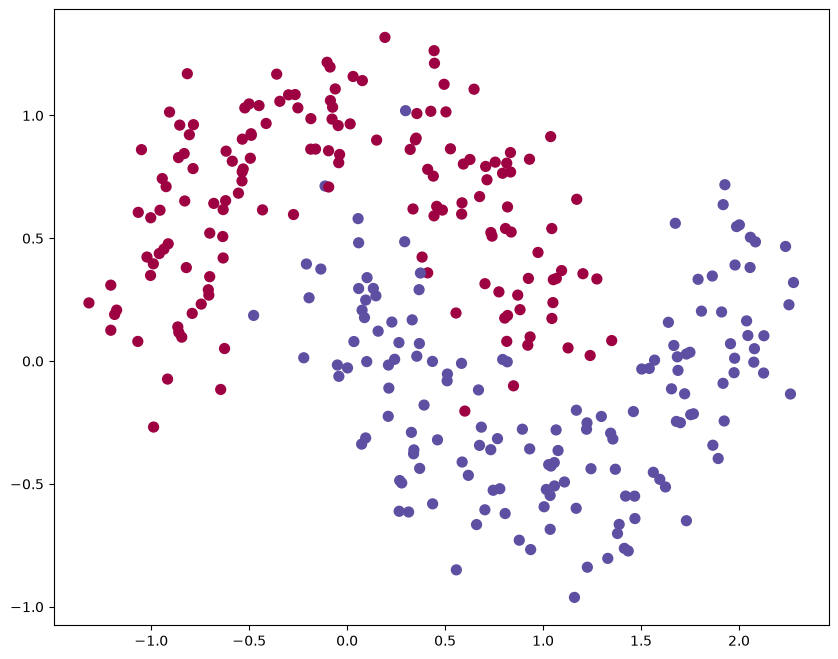

In [64]:
plt.scatter(X[:,0], X[:,1], s=50, c=y+1, cmap=plt.cm.Spectral)
plt.show()

The dataset we generated has two classes, represented by red and blue dots.

Our goal is to train a classifier that predicts the correct class from point coordinates $x_1$ et $x_2$. 

# Find the best line manually

In this part we will try to find the best line that separates our cloud of points manually.

<font color='red'><b>Question 2</b></font>  Creates a function that returns 1 if a coordinate point $(x_1,x_2$) is below the line with slope $a$ and the bias $b$.

In [65]:
def pred_linear(a: float, b: float, x1: float, x2: float):
    return 1 if x2 < a * x1 + b else 0

It is important to be able to evaluate the performance of our approaches using metrics. Here, we will choose the accuracy which is simply the number of well-classified elements divided by the total number of elements. To learn more about classification metrics like precision, recall and their link with accuracy, you can consult the following excellent Wikipedia (if you plan to do Machine Learning later, the notion of precision/recall is a classic) https://en.wikipedia.org/wiki/Precision_and_recall

<font color='red'><b>Question 3.</b></font> Complete the following accuracy function. (1 Python line with the comprehension of a list)

In [66]:
def accuracy(y_true, y_pred):
    """
    Args:
        y_true (list[int]): A list of integers having values in {0,1} that contain the class labels
        y_pred (list[int]): A list of integers having values in {0,1} that contain the predictions of the model    Returns:
        float: The Accuracy of the model
    
    Example:
    >>> accuracy([0,0,1], [0,1,1])
    0.666...
    """
    return sum(true == pred for true, pred in zip(y_true, y_pred)) / len(y_true)

In [67]:
#### display function
def plot_decision_boundary(pred_func):
    """
    Shows the decision boundaries of a binary prediction function.
    """
    # Set grid dimensions and give some margin for display
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    h = 0.01
    # Generate the grid of points with a distance of h between them
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    # Drawing the decision boundary
    Z = pred_func(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    # Show contour and training points
    plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Spectral)

<font color='red'><b>Question 4.</b></font>  Play by hand with parameters $a$ and $b$ to obtain several linear decision boundaries and try to obtain at least 80% accuracy.



le score obtenu est de:  0.8633333333333333


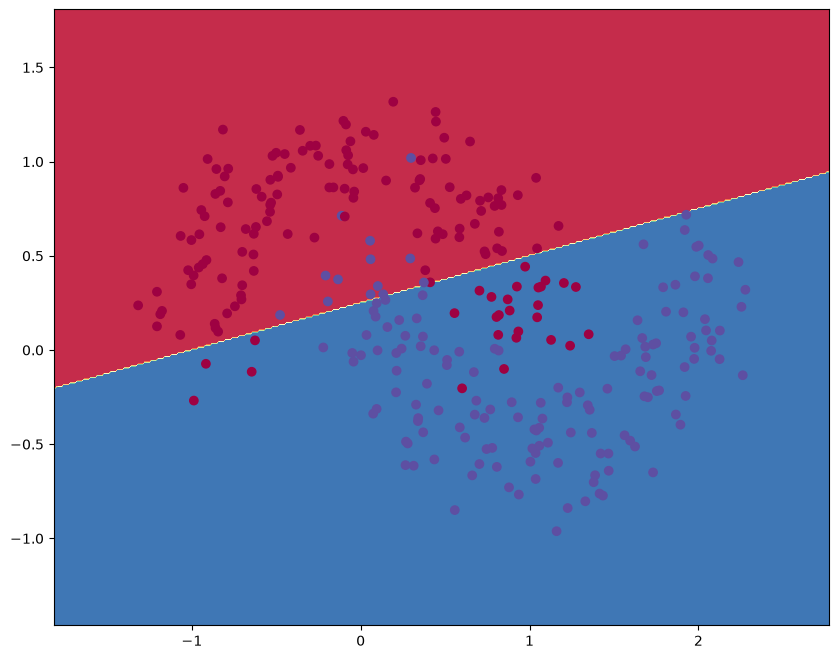

In [68]:
a = 0.25
b = 0.25
def prediction(A, a, b, func):
    return np.array([func(a=a, b=b, x1=x[0], x2=x[1]) for x in A])
plot_decision_boundary(lambda x: prediction(x, a, b, pred_linear))
print('le score obtenu est de: ', accuracy(y, prediction(X, a, b, pred_linear)))

# Logistic Regression

Scikit-learn has models such as logistic regression which can find the optimal parameters a and b:

In [69]:
classifier = sklearn.linear_model.LogisticRegressionCV()

 <font color='red'><b>Question 5.</b></font> Train this logistic regression model on the dataset (X,y). You can use the Scikit-learn documentation to see how to train a model on data: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

In [70]:
classifier.fit(X, y)

/home/hamza/serious_stuff/buildig_MLP/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/hamza/serious_stuff/buildig_MLP/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2116: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
/home/hamza/serious_stuff/buildig_MLP/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be 

,"Cs Cs: int or list of floats, default=10Each of the values in Cs describes the inverse of regularizationstrength. If Cs is as an int, then a grid of Cs values are chosenin a logarithmic scale between 1e-4 and 1e4.Like in support vector machines, smaller values specify strongerregularization.",10
,"l1_ratios l1_ratios: array-like of shape (n_l1_ratios), default=NoneFloats between 0 and 1 passed as Elastic-Net mixing parameter (scaling betweenL1 and L2 penalties). For `l1_ratio = 0` the penalty is an L2 penalty. For`l1_ratio = 1` it is an L1 penalty. For `0 < l1_ratio < 1`, the penalty is acombination of L1 and L2.All the values of the given array-like are tested by cross-validation and theone giving the best prediction score is used... warning:: Certain values of `l1_ratios`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `l1_ratios=None` is deprecated in 1.8 and will raise an error in version 1.10. Default value will change from `None` to `(0.0,)` in version 1.10.",'warn'
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"cv cv: int or cross-validation generator, default=NoneThe default cross-validation generator used is Stratified K-Folds.If an integer is provided, it specifies the number of folds, `n_folds`, used.See the module :mod:`sklearn.model_selection` module for thelist of possible cross-validation objects... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer dual=False whenn_samples > n_features.",False
,"penalty penalty: {'l1', 'l2', 'elasticnet'}, default='l2'Specify the norm of the penalty:- `'l2'`: add an L2 penalty term (used by default);- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"scoring scoring: str or callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: :ref:`accuracy <accuracy_score>` is used... versionchanged:: 1.11 The default will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11.",'warn'
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' might be slo

Once the model is trained, it can be used to predict and draw the decision boundary:

le score obtenu est de:  0.8566666666666667


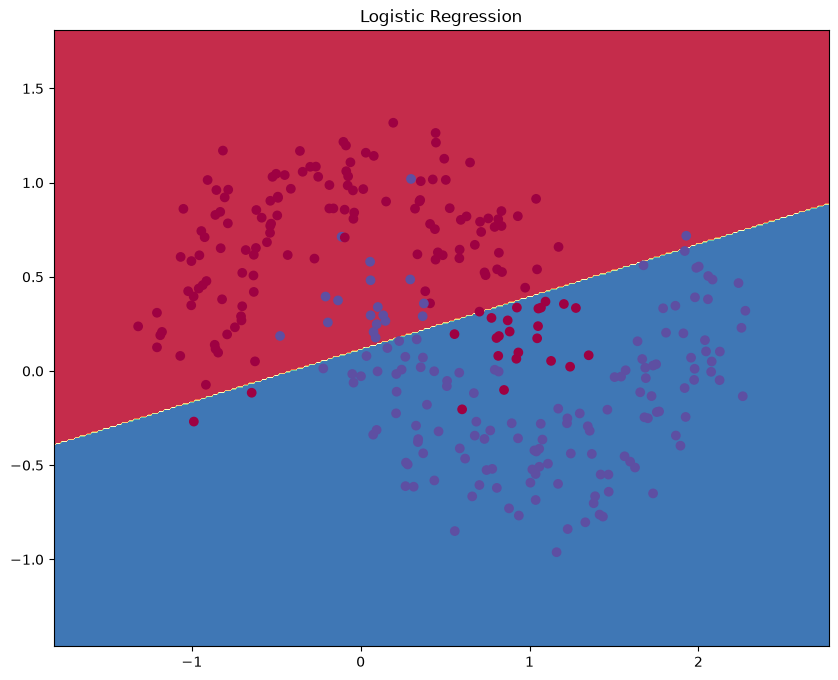

In [71]:
plot_decision_boundary(lambda x: classifier.predict(x))
plt.title("Logistic Regression")
print('le score obtenu est de: ', accuracy(y, classifier.predict(X)))

 <font color='red'><b>Question 6.</b></font> What do you observe? Was such a result predictable? What can we do to improve our predictions?

In [72]:
# The decision boundary is a straight line, because the logistic regression is a linear model.
# The moon shapes are curved, so its accuracy cannot be perfect.
# To improve we could add non-linear features or use a neural network with a hidden layer

<font color='red'><b>Bonus Question.</b></font> Find the coefficients $a, b$ obtained by Scikit-learn logistic regression.

In [73]:
# Decision boundary: w1*x1 + w2*x2 + bias = 0
w1, w2 = classifier.coef_[0]
bias = classifier.intercept_[0]
print(f"w1={w1:.3f}, w2={w2:.3f}, bias={bias:.3f}")
print(f"Line: x2 = {-w1/w2:.3f} * x1 + {-bias/w2:.3f}")

w1=1.286, w2=-4.606, bias=0.517
Line: x2 = 0.279 * x1 + 0.112


# Neural Networks

You will now create a neural network to solve the previous problem.

In [74]:
# We will reuse the same datasets as previously, be careful X and y will be global variables for the rest 
# (to be avoided in general, but simplifies the notations for this mini porject)
np.random.seed(1)
X, y = sklearn.datasets.make_moons(300, noise=0.20)

 <font color='red'><b> Question 7</b></font> Complete the following variables and functions to code a **two-layer** neural network (1 hidden layer). The hidden layer will currently have **10 neurons** and we will use a learning rate of 3e-2.


In [75]:
# number of examples in the training set

N = len(X)

# dimension of the input
d_input = X.shape[1]


# dimension of the output
d_output = 2  # class 0 or class 1

# dimension of the hidden layer i.e. number of neurons in the hidden layer
d_hidden = 10



# learning rate for the gradient descente algorithm
epsilon = 3e-2


 <font color='red'><b> Question 8</b></font> Complete the following function to generate the parameters of our neural network. For this you will use the random library to generate parameters in the interval [-0.5, 0.5] using the random.random() function.

In [76]:
import random

In [77]:
def init_model(d_input: int, d_hidden: int, d_output: int):
    """
    Args:
        d_input (int): dimension of the input
        d_hidden (int): dimension of the hidden layer
        d_output (int): dimension of the output

    Returns:
        dict: Dictionary containing 4 keys, the weights/biases (W1,b1) and (W2,b2) of the neural network.
        Each of these weights and biases are lists or list of lists of float.
    """
    # Initialization of random parameters
    random.seed(0)
    # First layer of size d_input x d_hidden
    W1 = [[random.random() - 0.5 for _ in range(d_hidden)] for _ in range(d_input)]
    # Bias of the first layer vector of size d_hidden
    b1 = [random.random() - 0.5 for _ in range(d_hidden)]
    # Second layer of size d_hidden x d_output
    W2 = [[random.random() - 0.5 for _ in range(d_output)] for _ in range(d_hidden)]
    # The bias of the second layer
    b2 = [random.random() - 0.5 for _ in range(d_output)]
    # The model returned at the end is a dictionary of weights and biases
    model = { 'W1': W1, 'b1': b1, 'W2': W2, 'b2': b2}
    return model

<font color='red'><b> Question 9</b></font> Implement the following mathematical functions which may be useful later. All vectors $v_1,v_2$ are python lists and the matrices $X$ and $W$ are lists of lists.

In [78]:
# dot product between two vectors
def dot_product(v1, v2):
    return sum(a * b for a, b in zip(v1, v2))

# Add two vectors
def add_bias(v1, v2):
    return [a + b for a, b in zip(v1, v2)]

# Get the columns number "index" of W
def get_columns(W, index):
    return [row[index] for row in W]

# Transpose a matrix
def transpose(W):
    return [get_columns(W, index) for index in range(len(W[0]))]

# Multiplication between two matrices()
def matrix_multiplication(X, W):
    return [[dot_product(row, get_columns(W, j)) for j in range(len(W[0]))] for row in X]


 <font color='red'><b> Question 10</b></font> Complete the forward_layer function by doing the following:
 $$ X \times W + b $$
 In which X represents the input, W the weights and and b the biases.
 Complete the sigmoid and feed_forward function.

In [79]:
def forward_layer(X, W, b):
    Z = matrix_multiplication(X, W)
    return [add_bias(row, b) for row in Z]

In [80]:
def sigmoid(x):
    """"
    Args:
        x (float): input
    returns:
        float : sigmoid(x)
    
    """
    if x >= 0:
        return 1.0 / (1.0 + exp(-x))
    e = exp(x)
    return e / (1.0 + e)

In [81]:
def forward_function(X,W1,b1,W2,b2):
    z1 = forward_layer(X, W1, b1)
    a1 = [[sigmoid(v) for v in row] for row in z1]
    z2 = forward_layer(a1, W2, b2)
    # Subtracting the maximum keeps exp() numerically stable.
    exp_scores = [[exp(v - max(row)) for v in row] for row in z2]# Compute exp(z2)
    probs = [[v / sum(row) for v in row] for row in exp_scores] #Apply softmax activation function on z2
    return probs
       

In [82]:
# Test your result:
np.random.seed(1)
model_test = init_model(4,3,2)
X_debug = [[random.random() for i in range(4)]] # Test with an example in dimension 2
forward_function(X_debug, model_test['W1'], model_test['b1'], model_test['W2'], model_test['b2'])

[[0.47916272248062897, 0.520837277519371]]

The two output probabilities must add up to 1. Their exact values depend on the initial weights and biases.

 <font color='red'><b> Question 11</b></font> We recall the feed forward equations (everything is in matrix form, so $X\in\mathbb{R}^{N\times d_{input}}$,$W_1\in\mathbb{R}^{d_{input }\times d_{hidden}}$, etc). Complete the back propagation equations and complete the sigmoid function, forward function and train_model. Gradient descent on W1 is provided to you.
Reminder on backprop : https://towardsdatascience.com/backpropagation-the-natural-proof-946c5abf63b1

$$
\begin{aligned}
z_1 & = XW_1 + b_1  \\ 
a_1 & = sigmoid(z_1)=\frac{1}{1+\exp(-z_1)} \\
z_2 & = a_1W_2 + b_2 \\
a_2 & = \hat{y} = \mathrm{softmax}(z_2)\\
L(y,\hat{y}) & = - \frac{1}{N} \sum_{n \in N} \sum_{i \in C} y_{n,i} \log\hat{y}_{n,i}
\end{aligned}
$$



Back propagation :
$$
\begin{aligned}
\delta_2 &= \hat{y} - y \\
\delta_1 &= (\delta_2 W_2^T) \odot a_1 \odot (1-a_1) \\
\frac{\partial L}{\partial W_2} &= a_1^T \delta_2, \quad \frac{\partial L}{\partial b_2} = \sum_n \delta_{2,n} \\
\frac{\partial L}{\partial W_1} &= X^T \delta_1, \quad \frac{\partial L}{\partial b_1} = \sum_n \delta_{1,n}
\end{aligned}
$$

In [83]:
def train_model(model, nn_hdim, num_epochs=1, print_loss=False):

    W1 = model['W1']
    b1 = model['b1']
    W2 = model['W2']
    b2 = model['b2']

    X_list = X.tolist() if hasattr(X, "tolist") else X
    labels = [int(value) for value in y]

    # Gradient descent. For each batch...
    for i in range(0, num_epochs):

        # Forward propagation (copy/paste inside forward_function previously defined)
        z1 = forward_layer(X_list, W1, b1)  # Output of the first layer
        a1 = [[sigmoid(value) for value in row] for row in z1] # Sigmoid activation of the first layer
        z2 = forward_layer(a1, W2, b2)  # Output of the second layer

        exp_scores = [
            [exp(value - max(row)) for value in row]
            for row in z2
        ] # Compute exp(z2)

        probs = [
            [value / sum(row) for value in row]
            for row in exp_scores
        ]

        # Estimate the loss (c)
        correct_logprobs = [
            -log(max(probs[n][labels[n]], 1e-300))
            for n in range(N)
        ] # Calculation of cross entropy for each example

        data_loss = 1. / N * sum(correct_logprobs) # Loss totale


        # Backpropagation
        delta2 = [
            [
                probability - (1.0 if class_index == labels[n] else 0.0)
                for class_index, probability in enumerate(row)
            ]
            for n, row in enumerate(probs)
        ]

        dW2 = matrix_multiplication(transpose(a1), delta2)
        db2 = [sum(column) for column in transpose(delta2)]

        delta1 = matrix_multiplication(delta2, transpose(W2))

        delta1 = [
            [
                gradient * activation * (1 - activation)
                for gradient, activation in zip(gradient_row, activation_row)
            ]
            for gradient_row, activation_row in zip(delta1, a1)
        ]

        dW1 = matrix_multiplication(transpose(X_list), delta1)
        db1 = [sum(column) for column in transpose(delta1)]

        # Gradient descente
        W1 = [
            [w - epsilon * d for d, w in zip(dW1_row, W1_row)]
            for dW1_row, W1_row in zip(dW1, W1)
        ]

        b1 = [b - epsilon * d for b, d in zip(b1, db1)]

        W2 = [
            [w - epsilon * d for d, w in zip(dW2_row, W2_row)]
            for dW2_row, W2_row in zip(dW2, W2)
        ]

        b2 = [b - epsilon * d for b, d in zip(b2, db2)]

        # Updating weights and biases
        model = {'W1': W1, 'b1': b1, 'W2': W2, 'b2': b2}

        # Loss display
        if print_loss and i % 50 == 0:
          print("Loss at epoch %i: %f" % (i, data_loss))

    return model

We will need a prediction function that uses our trained model to return predictions. Unlike the model outputs which are floats in [0,1] for each class, the model prediction is 1 on the class whose score is maximum and 0 elsewhere. We use numpy's argmax function to do this automatically.

<font color='red'><b> Question 12</b></font> Complete the function predict() :

In [84]:
def predict(model, x):
    W1, b1, W2, b2 = model['W1'], model['b1'], model['W2'], model['b2']

    # Forward propagation, like before
    z1 = forward_layer(x, W1, b1)
    a1 = [[sigmoid(v) for v in row] for row in z1]
    z2 = forward_layer(a1, W2, b2)

    exp_scores = np.exp(z2 - np.max(z2, axis=1, keepdims=True))
    probs = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

    return np.argmax(probs, axis=1)

<font color='red'><b> Question 13</b></font> Train the model for different number of epochs and comment on your results.

In [85]:
model = init_model(d_input,d_hidden,d_output)
model = train_model(model,d_hidden, num_epochs=200, print_loss=True)
print("The final accuracy obtained is :", accuracy(y, predict(model, X)))


Loss at epoch 0: 0.732492
Loss at epoch 50: 0.331724
Loss at epoch 100: 0.274587
Loss at epoch 150: 0.249642
The final accuracy obtained is : 0.9633333333333334


After 200 epochs, the MLP has an accuracy of about **96%**.

This is better than logistic regression, which had an accuracy of about **85%**.

Logistic regression can only draw a straight line to separate the two classes. The two moon shapes are curved, so a straight line is not enough.

The MLP has a hidden layer. It can learn a curved decision boundary, so it classifies the data better.


Text(0.5, 1.0, 'Decision Boundary for hidden layer size 10')

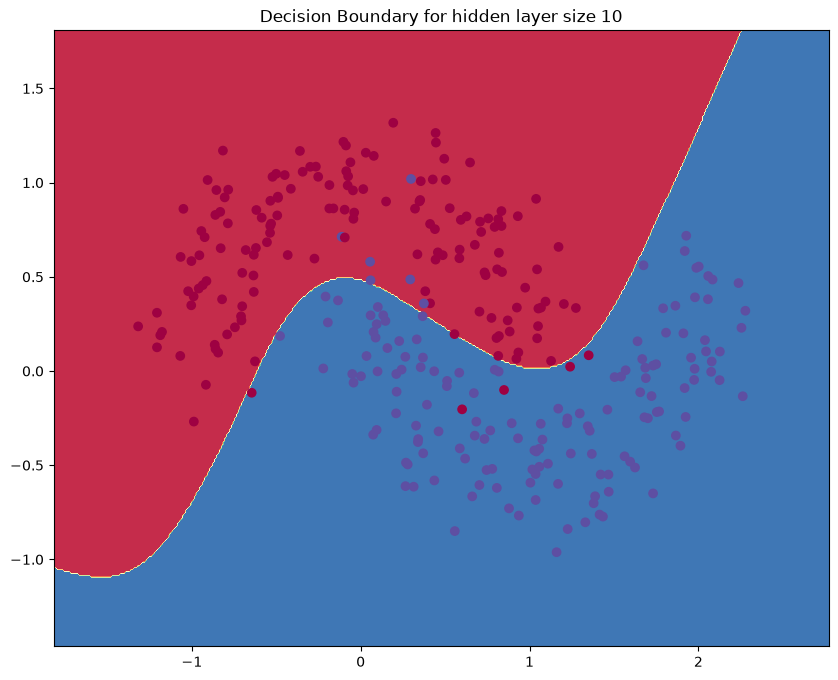

In [86]:
# Plot the decision boundary
plot_decision_boundary(lambda x: predict(model, x))
plt.title("Decision Boundary for hidden layer size 10")

# Application on a real dataset

We will now use scikit-learn's digits dataset. It contains 8 x 8 images of handwritten digits; it is different from MNIST, which contains 28 x 28 images.

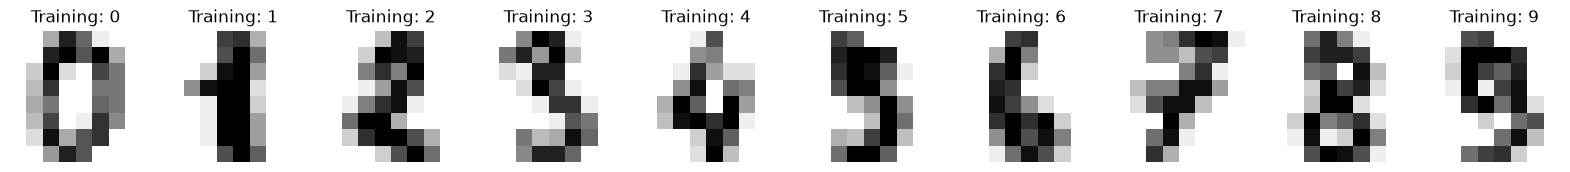

In [87]:
digits = sklearn.datasets.load_digits()
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))

_, axes = plt.subplots(nrows=1, ncols=10, figsize=(20, 3))
for ax, image, label in zip(axes, digits.images, digits.target):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation="nearest")
    ax.set_title("Training: %i" % label)

In [88]:
X =  digits.images.reshape((n_samples, -1)) # We reshape the images into vector

y = digits.target


<font color='red'><b> Question 13 </b></font> Complete the input and output dimensions of your network so that it is adapted to the MNIST Dataset and restart the training (be careful, the training will now take a few minutes without additional code optimization).


In [89]:
N = len(X) 
d_input = X.shape[1]  
d_output = 10  
d_hidden = 20 

# Gradient descent parameter
epsilon = 0.001  # le learning rate doit être plus petit qu'avant sinon l'entrainement diverge

In [90]:
model = init_model(d_input,d_hidden,d_output)
model = train_model(model,d_hidden, num_epochs=100, print_loss=True)
print("The final accuracy obtained is :", accuracy(y, predict(model, X)))


Loss at epoch 0: 2.877707
Loss at epoch 50: 0.390043
The final accuracy obtained is : 0.9755147468002225


<font color='red'><b> Question 14 </b></font> : 
Divide the MNIST dataset into training and validation datasets.
Find good hyper-parameters on your model. Why create a validation dataset?


We split the data into 80% training data and 20% validation data. The validation set is not used to change the weights. It measures how well the model works on new, unseen images and helps us choose hyperparameters without overfitting.


In [91]:
from sklearn.model_selection import train_test_split

# Split 80% training, 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Save original data
X_original, y_original, N_original = X, y, N

# Training data
X, y = X_train, y_train
N = len(X)

best_acc = 0
best_params = None

# Test different configurations
for hidden in [10, 20, 40]:
    for lr in [0.0003, 0.001, 0.003]:

        epsilon = lr

        model = init_model(X.shape[1], hidden, 10)
        model = train_model(model, hidden, num_epochs=50)

        train_acc = accuracy(y_train, predict(model, X_train))
        val_acc = accuracy(y_val, predict(model, X_val))

        print(f"Hidden={hidden}, LR={lr} | Train={train_acc:.3f} | Val={val_acc:.3f}")

        if val_acc > best_acc:
            best_acc = val_acc
            best_params = (hidden, lr)

# Restore original data
X, y, N = X_original, y_original, N_original

print("\nBest parameters:", best_params)
print("Best validation accuracy:", best_acc)

Hidden=10, LR=0.0003 | Train=0.744 | Val=0.756
Hidden=10, LR=0.001 | Train=0.753 | Val=0.742
Hidden=10, LR=0.003 | Train=0.740 | Val=0.761
Hidden=20, LR=0.0003 | Train=0.843 | Val=0.858
Hidden=20, LR=0.001 | Train=0.907 | Val=0.908
Hidden=20, LR=0.003 | Train=0.605 | Val=0.553
Hidden=40, LR=0.0003 | Train=0.900 | Val=0.864
Hidden=40, LR=0.001 | Train=0.936 | Val=0.908
Hidden=40, LR=0.003 | Train=0.095 | Val=0.131

Best parameters: (20, 0.001)
Best validation accuracy: 0.9083333333333333


We tested 9 different configurations by changing the number of hidden neurons and the learning rate. Each model was trained for 50 epochs.

The best configuration is **20 hidden neurons** with a learning rate of **0.001**.

It obtained about **90.7% training accuracy** and **90.8% validation accuracy**.

A learning rate of 0.003 gives worse results, especially with 20 or 40 hidden neurons. This learning rate is too high and training becomes unstable.


<font color='red'><b> Question 14 Bonus </b></font> 
How can you ensure that your accuracy on the validation set is significantly different from that of the training set? Find such hyperparameters and plot the accuracy on the training set and on the validation set during the training of your network (according to the epochs). What do you observe?

Epoch 20: Train=0.933, Val=0.314
Epoch 40: Train=1.000, Val=0.428
Epoch 60: Train=1.000, Val=0.472
Epoch 80: Train=1.000, Val=0.492
Epoch 100: Train=1.000, Val=0.511
Epoch 120: Train=1.000, Val=0.528
Epoch 140: Train=1.000, Val=0.536
Epoch 160: Train=1.000, Val=0.547
Epoch 180: Train=1.000, Val=0.553
Epoch 200: Train=1.000, Val=0.558


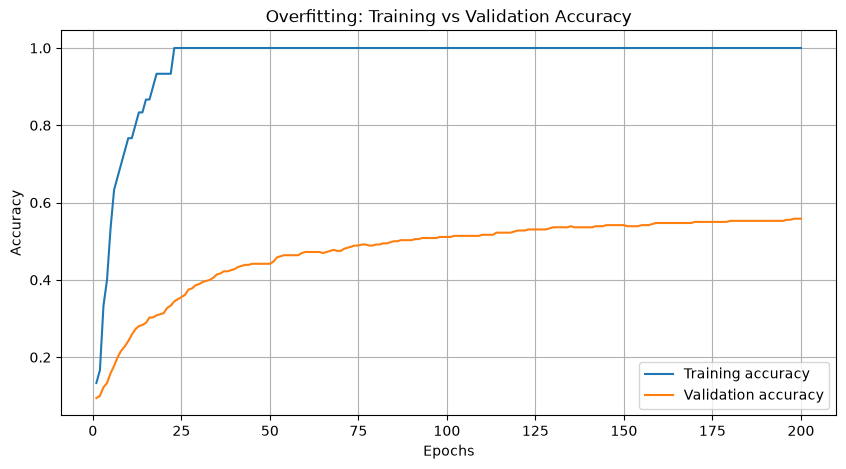

In [92]:
import matplotlib.pyplot as plt

# Use only 30 training examples to encourage overfitting
X_small = X_train[:30]
y_small = y_train[:30]

# Training data
X, y = X_small, y_small
N = len(X)

# Hyperparameters
hidden = 100
epsilon = 0.003
epochs = 200

# Initialize model
model = init_model(X.shape[1], hidden, 10)

train_accuracies = []
val_accuracies = []

# Training
for epoch in range(epochs):

    model = train_model(model, hidden, num_epochs=1)

    train_acc = accuracy(y_small, predict(model, X_small))
    val_acc = accuracy(y_val, predict(model, X_val))

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}: Train={train_acc:.3f}, Val={val_acc:.3f}")

# Plot
plt.figure(figsize=(10, 5))

plt.plot(range(1, epochs + 1), train_accuracies, label="Training accuracy")
plt.plot(range(1, epochs + 1), val_accuracies, label="Validation accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Overfitting: Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Restore the complete dataset.
X, y, N = X_original, y_original, N_original


To demonstrate overfitting, we reduced the training set to 30 examples and used a neural network with 100 hidden neurons.
The training accuracy quickly reached 100% after 60 epochs, while the validation accuracy remained significantly lower, reaching only 64.6% after 200 epochs.
We observe a large gap between training and validation accuracy, showing that the model fits the training data very well but struggles to generalize to unseen examples.

<font color='red'><b> Questions 15 (Bonus) </b></font> There are many ways to make your neural network more efficient, you can find out about the following points of improvement of your choice, explain their usefulness and implement those you want by analyzing the new results obtained (on the game of data of your choice). Don’t hesitate to be curious and look for good resources to help you!

* UUsing the Numpy library to handle matrix operations, rather than using Python lists of lists (this will simplify your code and should reduce training times by several orders of magnitude depending on the size of your network, allowing you to to train larger networks and better optimize hyperparameters on the MNIST dataset)
* Add Weight Decay (https://fr.wikipedia.org/wiki/Weight_decay) 
* Stochastic or Batch Gradient Descent (https://fr.wikipedia.org/wiki/Algorithme_du_gradient_stochastique)
* Added more layers (make the number of layers a model parameter)

In [100]:
import copy
import time


def init_model_numpy(list_model):
    return {key: np.array(value) for key, value in list_model.items()}

def forward_numpy(model, X):
    z1 = X @ model['W1'] + model['b1']
    a1 = 1 / (1 + np.exp(-z1))
    z2 = a1 @ model['W2'] + model['b2']
    exp_scores = np.exp(z2 - np.max(z2, axis=1, keepdims=True))
    probs = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)
    return a1, probs

def train_model_numpy(model, X, y, learning_rate, num_epochs):
    targets = np.eye(model['W2'].shape[1])[y]

    for _ in range(num_epochs):
        a1, probs = forward_numpy(model, X)

        # Backpropagation
        delta2 = probs - targets
        dW2 = a1.T @ delta2
        db2 = np.sum(delta2, axis=0)
        delta1 = (delta2 @ model['W2'].T) * a1 * (1 - a1)
        dW1 = X.T @ delta1
        db1 = np.sum(delta1, axis=0)

        # Gradient descent
        model['W1'] -= learning_rate * dW1
        model['b1'] -= learning_rate * db1
        model['W2'] -= learning_rate * dW2
        model['b2'] -= learning_rate * db2

    return model

def predict_numpy(model, X):
    _, probs = forward_numpy(model, X)
    return np.argmax(probs, axis=1)

# Compare both versions with the same data, hyperparameters and initial weights.
hidden = 20
learning_rate = 0.001
epochs = 50

X_saved, y_saved, N_saved, epsilon_saved = X, y, N, epsilon
X, y, N, epsilon = X_train, y_train, len(X_train), learning_rate

initial_model = init_model(X.shape[1], hidden, 10)

list_model = copy.deepcopy(initial_model)
start = time.perf_counter()
list_model = train_model(list_model, hidden, num_epochs=epochs)
list_time = time.perf_counter() - start
list_accuracy = accuracy(y_val, predict(list_model, X_val))

numpy_model = init_model_numpy(initial_model)
start = time.perf_counter()
numpy_model = train_model_numpy(numpy_model, X_train, y_train, learning_rate, epochs)
numpy_time = time.perf_counter() - start
numpy_accuracy = accuracy(y_val, predict_numpy(numpy_model, X_val))

print(f'List version:  accuracy = {list_accuracy:.3f}, time = {list_time:.3f} seconds')
print(f'NumPy version: accuracy = {numpy_accuracy:.3f}, time = {numpy_time:.3f} seconds')



List version:  accuracy = 0.908, time = 1.889 seconds
NumPy version: accuracy = 0.908, time = 0.029 seconds


We compared the performance of our neural network using Python lists and NumPy arrays.

Both implementations achieved the same validation accuracy of 90.8%.

However, the NumPy implementation was approximately 65 times faster, reducing the training time from 1.889 seconds to only 0.029 seconds.